## Breast Cancer Classification Using K-Nearest Neighbors (KNN)

**Algorithm-Based | Binary Classification**

**Dataset:** Wisconsin Diagnostic Breast Cancer (WDBC)  
**Classes:** Benign (B) and Malignant (M)

### Objective
Build a binary classification model using K-Nearest Neighbors, evaluate it using four distance metrics, and predict the class of an unseen sample.

> This is an educational machine-learning exercise, not a medical diagnostic tool.

##  Import required libraries
We use Pandas for data handling, Matplotlib/Seaborn for visualisation, and Scikit-learn for preprocessing and KNN.
import urllib.request
import io

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.datasets import load_breast_cancer
from pathlib import Path

## Download and load the dataset
The code first tries to download the original UCI CSV file. If the download is unavailable, it uses Scikit-learn's copy of the same Wisconsin Diagnostic Breast Cancer dataset so the notebook can still run.

In [15]:
cancer = load_breast_cancer()

df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

df["diagnosis"] = np.where(
    cancer.target == 0, "M", "B"
)

print("Dataset loaded successfully")
display(df.head())

Dataset loaded successfully


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


## Understand the dataset
Check the first rows, number of rows/columns, data types, and summary statistics.

In [16]:
print("First five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness erro

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


## Explore the target variable
The target variable is `diagnosis`. It must contain exactly two classes: B and M.

Target classes: <ArrowStringArray>
['M', 'B']
Length: 2, dtype: str

Class counts:
diagnosis
B    357
M    212
Name: count, dtype: int64


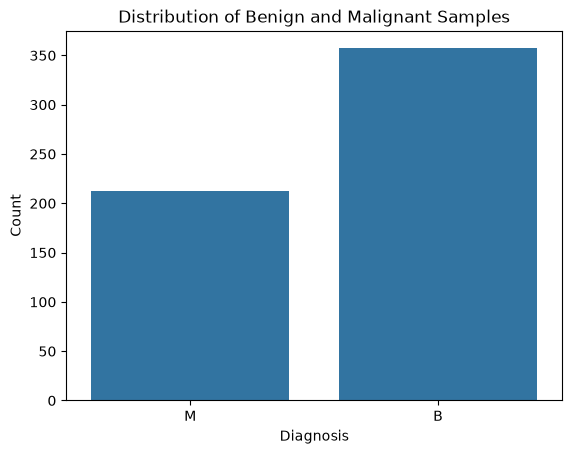

In [17]:
print("Target classes:", df["diagnosis"].unique())
print("\nClass counts:")
print(df["diagnosis"].value_counts())

sns.countplot(data=df, x="diagnosis")
plt.title("Distribution of Benign and Malignant Samples")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.show()

##  Data preprocessing
Remove the ID column because it is only an identifier. Check missing values and duplicates, then encode the target as 0 and 1. The feature columns are numeric.

In [18]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()
df = df.drop(columns=["ID"], errors="ignore")
df = df.dropna().copy()

# Make sure the target contains exactly two classes.
df["diagnosis"] = df["diagnosis"].astype(str).str.strip().str.upper()
df = df[df["diagnosis"].isin(["B", "M"])].copy()

# Encode target: B = 0, M = 1
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})

print("After preprocessing:", df.shape)
print("Target values:", sorted(df["diagnosis"].unique()))
print("Missing values after cleaning:", df.isnull().sum().sum())

Missing values: 0
Duplicate rows: 0
After preprocessing: (569, 31)
Target values: [np.int64(0), np.int64(1)]
Missing values after cleaning: 0


##  Separate input features (X) and target (y)
X contains the 30 numeric measurements. y contains the binary diagnosis.

In [19]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeature names:")
print(X.columns.tolist())

X shape: (569, 30)
y shape: (569,)

Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


## Split into training and testing sets
Use 80% for training and 20% for testing. `stratify=y` keeps the class proportions similar in both sets.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (455, 30)
Testing feature shape: (114, 30)
Training target shape: (455,)
Testing target shape: (114,)


##  Feature scaling using StandardScaler
KNN uses distances, so scaling is important. Fit the scaler only on training data to avoid data leakage.

In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)
print("First five scaled values:")
print(X_train_scaled[:5, :5])

Scaled training shape: (455, 30)
Scaled testing shape: (114, 30)
First five scaled values:
[[ 0.51855873  0.89182579  0.4246317   0.38392544 -0.97474371]
 [-0.51636409 -1.63971029 -0.54134872 -0.54296133  0.47621906]
 [-0.36811839  0.45551496 -0.38824993 -0.40297004 -1.43297929]
 [ 0.20528479  0.72616767  0.40033031  0.0706116   0.24325348]
 [ 1.2430047   0.19419511  1.21037678  1.20665201 -0.11144185]]


##  Train KNN and make predictions
Start with the Minkowski distance metric and `k=5`. Then compare predictions with the actual test labels.

In [22]:
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric="minkowski",
    p=2
)

knn_model.fit(X_train_scaled, y_train)
y_pred = knn_model.predict(X_test_scaled)

comparison = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    "Predicted": y_pred
})
display(comparison.head(15))

,Actual,Predicted
0,0,0
1,1,1
2,0,0
3,1,0
4,0,0
5,0,0
6,1,1
7,0,0
8,0,0
9,0,0


## Evaluate the model accuracy
Accuracy is the proportion of test samples classified correctly. Also review precision, recall, and F1-score.

KNN Accuracy (Minkowski, k=5): 0.9561

Classification Report:
               precision    recall  f1-score   support

   Benign (B)       0.95      0.99      0.97        72
Malignant (M)       0.97      0.90      0.94        42

     accuracy                           0.96       114
    macro avg       0.96      0.95      0.95       114
 weighted avg       0.96      0.96      0.96       114



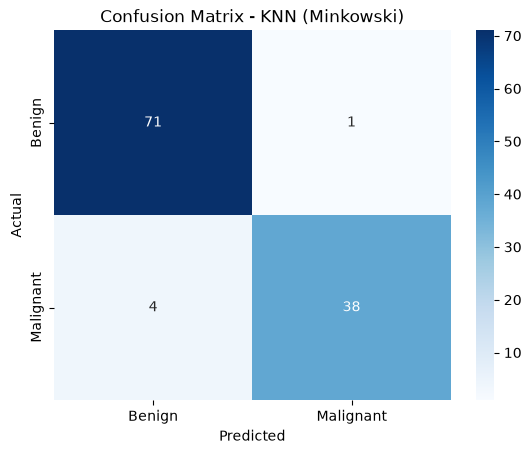

In [23]:
accuracy = accuracy_score(y_test, y_pred)
print(f"KNN Accuracy (Minkowski, k=5): {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Benign (B)", "Malignant (M)"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)
plt.title("Confusion Matrix - KNN (Minkowski)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

##  Experiment with different distance metrics

We compare the required metrics using the same train/test split and the same scaled data.

- **Minkowski:** General distance; with `p=2`, it is Euclidean distance.
- **Manhattan:** Sum of absolute differences between feature values.
- **Hamming:** Proportion of feature positions that differ. For continuous scaled measurements, this metric is less natural than the others, but it is included because the task requires it.
- **Chebyshev:** Maximum absolute difference across features.

In [24]:
metrics = ["minkowski", "manhattan", "hamming", "chebyshev"]
results = []

for metric_name in metrics:
    model = KNeighborsClassifier(
        n_neighbors=5,
        metric=metric_name,
        p=2
    )
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    score = accuracy_score(y_test, predictions)

    results.append({
        "Distance Metric": metric_name.capitalize(),
        "Accuracy": score
    })

results_df = pd.DataFrame(results).sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

display(results_df)

,Distance Metric,Accuracy
0,Minkowski,0.956140
1,Manhattan,0.956140
2,Chebyshev,0.912281
3,Hamming,0.666667


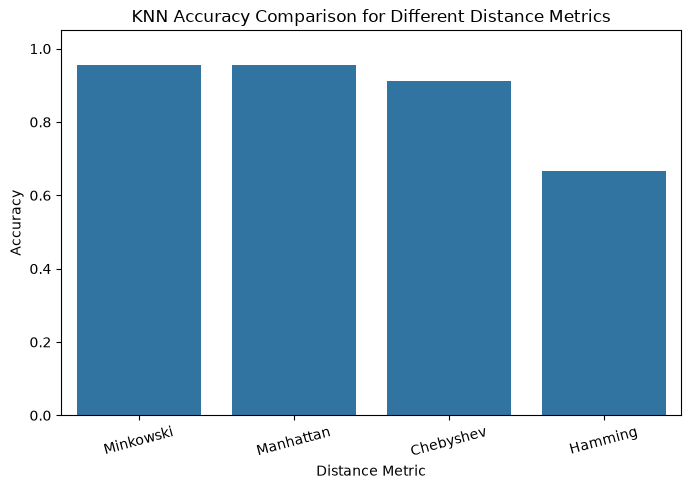

Best metric in this experiment: minkowski
Best accuracy: 0.9561


In [25]:
plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="Distance Metric", y="Accuracy")
plt.ylim(0, 1.05)
plt.title("KNN Accuracy Comparison for Different Distance Metrics")
plt.ylabel("Accuracy")
plt.xlabel("Distance Metric")
plt.xticks(rotation=15)
plt.show()

best_metric = results_df.loc[0, "Distance Metric"].lower()
best_accuracy = results_df.loc[0, "Accuracy"]
print(f"Best metric in this experiment: {best_metric}")
print(f"Best accuracy: {best_accuracy:.4f}")

##  Predict a new / unseen data point
We take one row from the test set that was not used during training. This acts as an unseen example for the trained model. The model predicts its class.

In [26]:
# Select one sample from the test set (not used to train the model).
new_sample = X_test.iloc[[0]]
new_sample_scaled = scaler.transform(new_sample)

# Use the best metric found in the comparison.
if best_metric == "minkowski":
    final_model = KNeighborsClassifier(n_neighbors=5, metric="minkowski", p=2)
else:
    final_model = KNeighborsClassifier(n_neighbors=5, metric=best_metric)

final_model.fit(X_train_scaled, y_train)
new_prediction = final_model.predict(new_sample_scaled)[0]

class_names = {0: "Benign (B)", 1: "Malignant (M)"}
print("Predicted class for unseen sample:", class_names[new_prediction])
print("Predicted numeric label:", new_prediction)

Predicted class for unseen sample: Benign (B)
Predicted numeric label: 0


## Final conclusion
In this project, we performed binary classification using the Wisconsin Diagnostic Breast Cancer dataset and the K-Nearest Neighbors algorithm. We explored and preprocessed the data, split it into training and testing sets, applied StandardScaler, trained KNN models using four distance metrics, compared their accuracies, and predicted the class of an unseen sample.

The best metric is the one with the highest test accuracy in your run. Results can vary if you change the split, random state, or KNN settings. This project is for learning only and must not be used to make medical decisions.